# Maxar ship detection — single-vessel test
Runs the DOTA v1.5 ship-only **YOLO11s-OBB** model (`best.pt`, trained at 512 px) on a Maxar Open Data scene over Nuku'alofa.

Workflow: crop a small window around one vessel → tile it at native resolution → merge detections → export PNG + GeoJSON (EPSG:32701) for QGIS.

The Maxar image is streamed directly from the public S3 bucket, so nothing needs to be uploaded. Training is in `Shipdetection_dota.ipynb`.

## 1. Install

In [1]:
%pip install -q ultralytics rasterio shapely

## 2. Mount Google Drive and find `best.pt`
The weights are in *Shared with me → tonga-vessels-data → Dota V1.5 Ship detection…*. Because there is a shortcut in My Drive, they appear under `/content/drive/MyDrive/`.
If the search finds more than one file, or none, set `MODEL_PATH` by hand. In the Colab file browser, right-click the file and choose *Copy path*.

In [2]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

MODEL_PATH = None   # e.g. "/content/drive/MyDrive/tonga-vessels-data/Dota V1.5 Ship detection/best.pt"

if MODEL_PATH is None:
    my_drive = Path("/content/drive/MyDrive")
    # Look only inside folders/shortcuts that look relevant (a full-Drive search is slow)
    roots = [p for p in my_drive.iterdir()
             if any(k in p.name.lower() for k in ("tonga", "dota", "ship"))]
    candidates = [f for r in roots for f in ([r] if r.is_file() else r.rglob("best*.pt"))
                  if f.suffix == ".pt"]
    for c in candidates:
        print("found:", c)
    if not candidates:
        raise FileNotFoundError(
            "No best.pt found under shortcuts named tonga/dota/ship in My Drive. "
            "Set MODEL_PATH manually.")
    MODEL_PATH = str(candidates[0])

print("Using model:", MODEL_PATH)

Mounted at /content/drive
found: /content/drive/MyDrive/tonga-vessels-data/Dota V1.5 Ship detection model & results/best.pt
Using model: /content/drive/MyDrive/tonga-vessels-data/Dota V1.5 Ship detection model & results/best.pt


Detected vessel  tile 300222120132 | WorldView-2 | product GSD 0.31 m (native 0.53 m) | detections in 300 m window: 1
    in view: conf 0.70, ~33.7 m x 7.3 m
Missed vessel    tile 300222120123 | WorldView-3 | product GSD 0.31 m (native 0.41 m) | detections in 300 m window: 0
False positive   tile 300222120123 | WorldView-3 | product GSD 0.31 m (native 0.41 m) | detections in 300 m window: 1
    in view: conf 0.18, ~4.5 m x 1.5 m
Saved: /content/ship_detection/figures/fig_obb_maxar_transfer.png
Saved: /content/ship_detection/figures/fig_obb_maxar_transfer.pdf


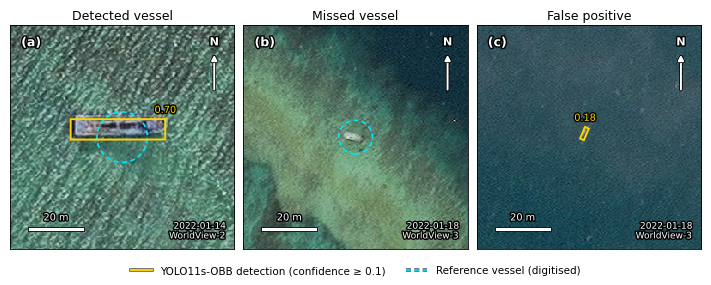

In [51]:
# ============================================================
# FIGURE: YOLO11s-OBB transfer test on Maxar imagery
# Three panels: (a) detected vessel, (b) missed vessel, (c) false positive
# Add as a new cell after section 2 (it needs MODEL_PATH). Everything else is self-contained.
# ============================================================
import numpy as np
import rasterio
import torch
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Polygon as MplPolygon, Circle, Rectangle
from matplotlib.lines import Line2D
from pathlib import Path
from rasterio.enums import Resampling
from rasterio.windows import Window, bounds as window_bounds
from shapely.geometry import Polygon
from ultralytics import YOLO

# ---------- 1. FILL IN: the three examples -------------------------------
# centre : (x, y) in EPSG:32701, read from QGIS. Centre (c) on the false detection itself.
# scene  : one of the keys in CATALOG below
# ref_m  : rough length of the reference vessel in metres (sets the dashed ring). None = no vessel.
EXAMPLES = [
    dict(label="Detected vessel", scene="2022-01-14", centre=(691613.0, 7662151.0), ref_m=12),
    dict(label="Missed vessel",   scene="2022-01-18a", centre=(688485.0, 7662989.0), ref_m=8),
    dict(label="False positive", scene="2022-01-18a",
     centre=(685560.0, 7664918.0) ,
     run_centre=(685560.0, 7664918.0) ,
     ref_m=None),
]

# ---------- 2. Settings ----------------------------------------------------
CONF = 0.1            # same threshold as the DOTA test results; state it in the caption
UPSCALE = 1            # same as the exploratory runs
CONTEXT_HALF_M = 150   # inference window (300 m x 300 m), identical to the exploratory runs
VIEW_HALF_M = 40       # half-width of what is shown in each panel (80 m x 80 m)
SCALEBAR_M = 20
TILE, OVERLAP, MERGE_OVERLAP, WHOLE_CROP_MAX = 512, 128, 0.5, 2048

DET_COLOUR = "#FFD400"   # OBB detections (solid)
REF_COLOUR = "#00E5FF"   # reference vessel (dashed ring)
FIG_DIR = Path("/content/ship_detection/figures")

# Maxar Open Data, Tonga volcano event: date folder, catalog ID, sensor, native GSD
CATALOG = {
    "2022-01-14":  ("2022-01-14", "10300100CCD4E100", "WorldView-2", 0.53),
    "2022-01-17":  ("2022-01-17", "10300100CDADC400", "WorldView-2", 0.51),
    "2022-01-18a": ("2022-01-18", "1040010072C90800", "WorldView-3", 0.41),
    "2022-01-18b": ("2022-01-18", "10400100718A2000", "WorldView-3", 0.42),
}
S3 = "/vsicurl/https://maxar-opendata.s3.amazonaws.com/events/tonga-volcano21/ard/01"

import os
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
os.environ["CPL_VSIL_CURL_ALLOWED_EXTENSIONS"] = ".tif"


# ---------- 3. Helpers -----------------------------------------------------
def quadkey_from_utm(x, y, level=12, tile_m=5000.0):
    """Maxar ARD tile for a point in UTM 1S: 2^12 x 2^12 tiles of 5 km centred on (500 000, 10 000 000)."""
    half = tile_m * 2 ** level / 2
    tx = int((x - (500_000 - half)) // tile_m)
    ty = int(((10_000_000 + half) - y) // tile_m)
    return "".join(str(((tx >> i) & 1) + 2 * ((ty >> i) & 1)) for i in range(level - 1, -1, -1))


def infer(rgb, model, device):
    """Same inference and merge logic as section 6."""
    H, W = rgb.shape[:2]
    dets = []

    def starts(n):
        if n <= TILE:
            return [0]
        s = list(range(0, n - TILE + 1, TILE - OVERLAP))
        if s[-1] != n - TILE:
            s.append(n - TILE)
        return s

    if max(H, W) <= WHOLE_CROP_MAX:
        imgsz = int(np.ceil(max(H, W) / 32) * 32)
        r = model.predict(rgb[:, :, ::-1].copy(), imgsz=imgsz, conf=CONF, device=device, verbose=False)[0]
        if r.obb is not None:
            for pts, c in zip(r.obb.xyxyxyxy.cpu().numpy(), r.obb.conf.cpu().numpy()):
                dets.append((Polygon(pts), float(c)))
    else:
        for y0 in starts(H):
            for x0 in starts(W):
                tile = rgb[y0:y0 + TILE, x0:x0 + TILE]
                if tile.shape[0] < TILE or tile.shape[1] < TILE:
                    pad = np.zeros((TILE, TILE, 3), np.uint8)
                    pad[:tile.shape[0], :tile.shape[1]] = tile
                    tile = pad
                r = model.predict(tile[:, :, ::-1].copy(), imgsz=TILE, conf=CONF, device=device, verbose=False)[0]
                if r.obb is None:
                    continue
                for pts, c in zip(r.obb.xyxyxyxy.cpu().numpy(), r.obb.conf.cpu().numpy()):
                    dets.append((Polygon(pts + np.array([x0, y0])), float(c)))

    dets.sort(key=lambda d: d[1], reverse=True)
    kept = []
    for poly, c in dets:
        if all(poly.intersection(k[0]).area / min(poly.area, k[0].area) < MERGE_OVERLAP for k in kept):
            kept.append((poly, c))
    return kept


def run_example(ex, model, device):
    date_dir, cat_id, sensor, native_gsd = CATALOG[ex["scene"]]
    cx, cy = ex["centre"]
    qk = quadkey_from_utm(cx, cy)
    url = f"{S3}/{qk}/{date_dir}/{cat_id}-visual.tif"
    try:
        src = rasterio.open(url)
    except rasterio.errors.RasterioIOError:
        raise RuntimeError(f"'{ex['label']}': scene {ex['scene']} has no image in tile {qk}. "
                           "Try another scene key (2022-01-18a covers the full Nuku'alofa tile).")
    with src:
        b = src.bounds
        if not (b.left <= cx <= b.right and b.bottom <= cy <= b.top):
            raise RuntimeError(f"'{ex['label']}': centre is outside tile {qk}.")
        gsd = abs(src.transform.a)
        row, col = src.index(cx, cy)
        half_px = int(round(CONTEXT_HALF_M / gsd))
        col0, row0 = max(col - half_px, 0), max(row - half_px, 0)
        w, h = min(2 * half_px, src.width - col0), min(2 * half_px, src.height - row0)
        win = Window(col0, row0, w, h)
        arr = src.read([1, 2, 3], window=win, out_shape=(3, int(h * UPSCALE), int(w * UPSCALE)),
                       resampling=Resampling.bilinear)
        wt = src.window_transform(win)
        left, bottom, right, top = window_bounds(win, src.transform)

    rgb = np.ascontiguousarray(np.moveaxis(arr, 0, -1))
    if rgb.max() == 0:
        raise RuntimeError(f"'{ex['label']}': no data at this point in {ex['scene']} "
                           "(outside that pass's footprint). Try another scene key.")

    dets = []
    for poly, c in infer(rgb, model, device):
        xy = np.array([wt * (px / UPSCALE, py / UPSCALE) for px, py in poly.exterior.coords]) - [cx, cy]
        rect = np.array(Polygon(xy).minimum_rotated_rectangle.exterior.coords)
        sides = sorted(np.hypot(*np.diff(rect, axis=0).T)[:4])
        dets.append(dict(xy=xy, conf=c, length_m=sides[-1], width_m=sides[0]))

    return dict(rgb=rgb, extent=(left - cx, right - cx, bottom - cy, top - cy), dets=dets,
                gsd=gsd, sensor=sensor, native_gsd=native_gsd, quadkey=qk)


def draw_panel(ax, ex, res, letter):
    V = VIEW_HALF_M
    halo = [pe.withStroke(linewidth=2, foreground="black")]

    ax.imshow(res["rgb"], extent=res["extent"], interpolation="none")
    ax.set_xlim(-V, V)
    ax.set_ylim(-V, V)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_linewidth(0.6)

    # reference vessel
    if ex["ref_m"]:
        ax.add_patch(Circle((0, 0), radius=max(0.75 * ex["ref_m"], 4), fill=False,
                            ec=REF_COLOUR, lw=1.2, ls=(0, (3, 2))))

    # detections inside the view
    for d in res["dets"]:
        mx, my = d["xy"][:-1].mean(axis=0)
        if abs(mx) > V or abs(my) > V:
            continue
        ax.add_patch(MplPolygon(d["xy"], closed=True, fill=False, ec=DET_COLOUR, lw=1.4))
        tx, ty = d["xy"][np.argmax(d["xy"][:, 1])]
        ax.text(tx, ty + 1.5, f"{d['conf']:.2f}", color=DET_COLOUR, fontsize=7,
                ha="center", va="bottom", path_effects=halo, clip_on=True)

    # scale bar (bottom left)
    x0, y0 = -V + 0.08 * 2 * V, -V + 0.08 * 2 * V
    ax.add_patch(Rectangle((x0, y0), SCALEBAR_M, 0.018 * 2 * V, fc="white", ec="black", lw=0.6))
    ax.text(x0 + SCALEBAR_M / 2, y0 + 0.04 * 2 * V, f"{SCALEBAR_M} m", color="white",
            fontsize=7, ha="center", va="bottom", path_effects=halo)

    # north arrow (top right). UTM grid north; convergence here is < 1 degree.
    nx = V - 0.09 * 2 * V
    ax.annotate("", xy=(nx, V - 0.12 * 2 * V), xytext=(nx, V - 0.30 * 2 * V),
                arrowprops=dict(arrowstyle="-|>", color="white", lw=1.4,
                                path_effects=[pe.withStroke(linewidth=2.6, foreground="black")]))
    ax.text(nx, V - 0.10 * 2 * V, "N", color="white", fontsize=8, fontweight="bold",
            ha="center", va="bottom", path_effects=halo)

    # panel letter and scene info
    ax.text(-V + 0.05 * 2 * V, V - 0.05 * 2 * V, letter, color="white", fontsize=9,
            fontweight="bold", ha="left", va="top", path_effects=halo)
    ax.text(V - 0.04 * 2 * V, -V + 0.04 * 2 * V, f"{ex['scene'][:10]}\n{res['sensor']}",
            color="white", fontsize=6.5, ha="right", va="bottom", linespacing=1.1, path_effects=halo)
    ax.set_title(ex["label"], fontsize=9, pad=4)


# ---------- 4. Run and plot -----------------------------------------------
assert all(ex["centre"][0] > 0 for ex in EXAMPLES), "Fill in the three centres in EXAMPLES first."

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8})
device = 0 if torch.cuda.is_available() else "cpu"
obb_model = YOLO(MODEL_PATH)

results = []
for ex in EXAMPLES:
    res = run_example(ex, obb_model, device)
    results.append(res)
    print(f"{ex['label']:16s} tile {res['quadkey']} | {res['sensor']} | product GSD {res['gsd']:.2f} m "
          f"(native {res['native_gsd']} m) | detections in 300 m window: {len(res['dets'])}")
    for d in res["dets"]:
        if abs(d["xy"][:-1, 0].mean()) <= VIEW_HALF_M and abs(d["xy"][:-1, 1].mean()) <= VIEW_HALF_M:
            print(f"    in view: conf {d['conf']:.2f}, ~{d['length_m']:.1f} m x {d['width_m']:.1f} m")

fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.75), layout="constrained")
for ax, ex, res, letter in zip(axes, EXAMPLES, results, "abc"):
    draw_panel(ax, ex, res, f"({letter})")

handles = [
    Line2D([], [], color=DET_COLOUR, lw=1.4, label=f"YOLO11s-OBB detection (confidence ≥ {CONF})"),
    Line2D([], [], color=REF_COLOUR, lw=1.2, ls=(0, (3, 2)), label="Reference vessel (digitised)"),
]
leg = fig.legend(handles=handles, loc="outside lower center", ncol=2, frameon=False, fontsize=7.5)
for line in leg.get_lines():
    line.set_path_effects([pe.withStroke(linewidth=2.6, foreground="0.35")])

FIG_DIR.mkdir(parents=True, exist_ok=True)
for ext in ("png", "pdf"):
    out = FIG_DIR / f"fig_obb_maxar_transfer.{ext}"
    fig.savefig(out, dpi=600, bbox_inches="tight", facecolor="white")
    print("Saved:", out)
plt.show()

# Optional: copy to Drive next to the model
# import shutil
# for f in FIG_DIR.glob("fig_obb_maxar_transfer.*"):
#     shutil.copy(f, Path(MODEL_PATH).parent / f.name)

## 3. Choose the Maxar scene
Quadkey **300222120123** covers Nuku'alofa. All scenes are in EPSG:32701.

| key | date (UTC) | sensor | GSD | cloud | coverage of tile |
|---|---|---|---|---|---|
| `2022-01-14` | 22:05 | WV-2 | 0.53 m | 7 % | southern strip |
| `2022-01-17` | 21:54 | WV-2 | 0.51 m | 41 % | southern strip |
| `2022-01-18a` | 21:43:36 | WV-3 | 0.41 m | 37 % | **full tile** |
| `2022-01-18b` | 21:43:49 | WV-3 | 0.42 m | 31 % | western part only (x < 687 590) |

In [24]:
import os
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"   # faster remote COG reads
os.environ["CPL_VSIL_CURL_ALLOWED_EXTENSIONS"] = ".tif"

QUADKEY = "300222120123"   # 121 = north (outer lagoon), 123 = waterfront, 130 = north-east
SCENE = "2022-01-18a"
BASE = f"/vsicurl/https://maxar-opendata.s3.amazonaws.com/events/tonga-volcano21/ard/01/{QUADKEY}"

SCENES = {
    "2022-01-14":  f"{BASE}/2022-01-14/10300100CCD4E100-visual.tif",
    "2022-01-17":  f"{BASE}/2022-01-17/10300100CDADC400-visual.tif",
    "2022-01-18a": f"{BASE}/2022-01-18/1040010072C90800-visual.tif",
    "2022-01-18b": f"{BASE}/2022-01-18/10400100718A2000-visual.tif",
}
TIFF_PATH = SCENES[SCENE]

print(SCENE, QUADKEY, "->", TIFF_PATH)

2022-01-18a 300222120123 -> /vsicurl/https://maxar-opendata.s3.amazonaws.com/events/tonga-volcano21/ard/01/300222120123/2022-01-18/1040010072C90800-visual.tif


## 4. Overview of the scene — find the vessel
Shows a low-resolution preview with UTM coordinates on the axes. Use it, or QGIS in EPSG:32701, to read the centre of the vessel you want to test. The preview comes from the file's built-in overviews, so it loads quickly.

Size 17408 x 17408 px | GSD 0.31 m | CRS EPSG:32701
Bounds x 684844–690156, y 7659844–7665156


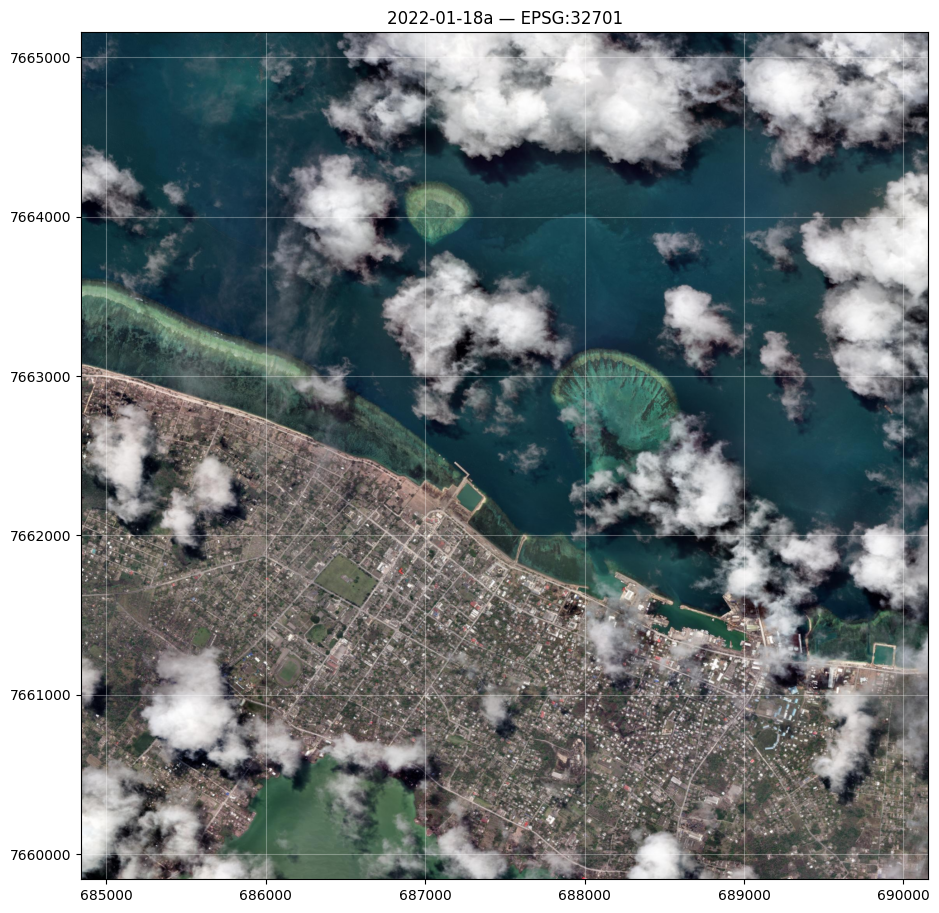

In [25]:
import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

PREVIEW_PX = 2000

with rasterio.open(TIFF_PATH) as src:
    scale = max(src.width, src.height) / PREVIEW_PX
    ov = src.read([1, 2, 3],
                  out_shape=(3, int(src.height / scale), int(src.width / scale)),
                  resampling=Resampling.average)
    b = src.bounds
    print(f"Size {src.width} x {src.height} px | GSD {abs(src.transform.a):.2f} m | CRS {src.crs}")
    print(f"Bounds x {b.left:.0f}–{b.right:.0f}, y {b.bottom:.0f}–{b.top:.0f}")

fig, ax = plt.subplots(figsize=(11, 11))
ax.imshow(np.moveaxis(ov, 0, -1), extent=(b.left, b.right, b.bottom, b.top))
ax.ticklabel_format(useOffset=False, style="plain")
ax.grid(color="white", alpha=0.3)
ax.set_title(f"{SCENE} — EPSG:32701")
plt.show()

## 5. Settings
`CENTRE` is the middle of the vessel. Use EPSG:32701 `(x, y)` read from the overview or QGIS, or EPSG:4326 `(lon, lat)`.

- `UPSCALE = 2` helps if the boat is short (< ~20 px ≈ 8–10 m at 0.41–0.53 m GSD).
- `CONF = 0.10` is deliberately low for exploration; report at 0.25 to match the DOTA tests.
- **Control test:** also run once with `CENTRE` on empty water. Any detections there are false positives (whitecaps, glint).

In [49]:
CENTRE = (685560.0, 7664918.0)      # e.g. (688900, 7661500)
CENTRE_CRS = "EPSG:32701"

HALF_SIZE_M = 150      # crop = 300 m x 300 m
UPSCALE = 1
TILE = 512             # training size
OVERLAP = 128
CONF = 0.1
MERGE_OVERLAP = 0.5    # drop a box if >50 % of it lies inside a higher-scoring box
WHOLE_CROP_MAX = 2048  # crops up to this size run in ONE pass (no tile cuts)

OUT_DIR = Path("/content/ship_detection/single_vessel")

## 6. Run detection

Run tag: run014_2022-01-18a_x685560_y7664918_up1_c0.1
GSD 0.31 m | crop 984x984 px -> 984x984 px (upscale x1)
Inference: whole crop | raw detections: 1 | after merge: 1
  #0: conf 0.18, ~4.5 m x 1.5 m
Saved: /content/ship_detection/single_vessel/detections_run014_2022-01-18a_x685560_y7664918_up1_c0.1.geojson
Saved: /content/ship_detection/single_vessel/detections_run014_2022-01-18a_x685560_y7664918_up1_c0.1.png


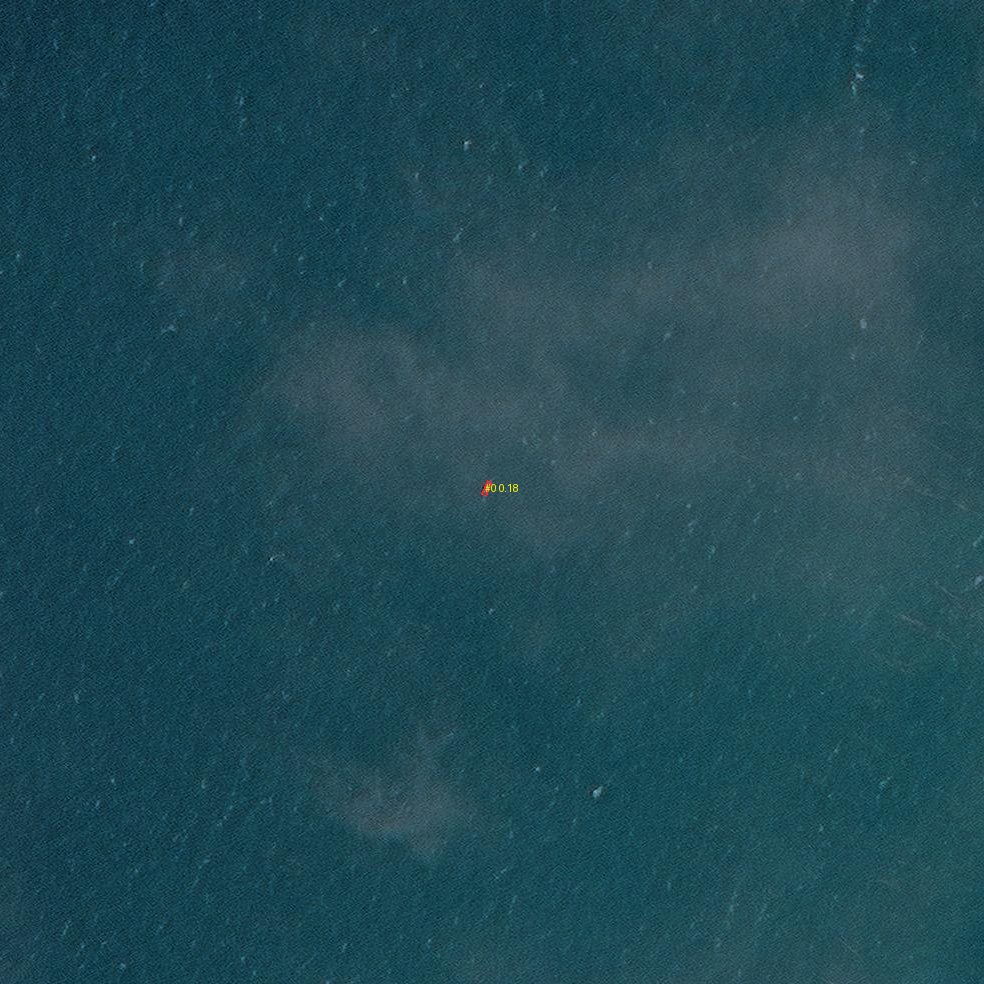

In [50]:
import json
import torch
from rasterio.windows import Window
from rasterio.warp import transform as warp_transform
from shapely.geometry import Polygon, mapping
from PIL import Image, ImageDraw
from IPython.display import display
from ultralytics import YOLO

device = 0 if torch.cuda.is_available() else "cpu"
model = YOLO(MODEL_PATH)


def detect_vessel(tiff_path, centre, centre_crs="EPSG:32701", half_size_m=150,
                  upscale=1, conf=0.10, tag="run"):
    if centre is None:
        raise ValueError("Set CENTRE in section 5 first.")

    # ---- read the crop -------------------------------------------------
    with rasterio.open(tiff_path) as src:
        gsd = abs(src.transform.a)
        xs, ys = warp_transform(centre_crs, src.crs, [centre[0]], [centre[1]])
        row, col = src.index(xs[0], ys[0])
        half_px = int(round(half_size_m / gsd))
        col0, row0 = max(col - half_px, 0), max(row - half_px, 0)
        w = min(2 * half_px, src.width - col0)
        h = min(2 * half_px, src.height - row0)
        if w <= 0 or h <= 0 or col < 0 or row < 0:
            raise ValueError("CENTRE is outside this scene. Check CENTRE / CENTRE_CRS / SCENE.")
        win = Window(col0, row0, w, h)
        crop = src.read([1, 2, 3], window=win,
                        out_shape=(3, int(h * upscale), int(w * upscale)),
                        resampling=Resampling.bilinear)
        win_transform = src.window_transform(win)
        crs = src.crs

    rgb = np.ascontiguousarray(np.moveaxis(crop, 0, -1))
    if rgb.max() == 0:
        print("Warning: crop is empty (no-data). The vessel may be outside this pass's footprint.")
    H, W = rgb.shape[:2]
    print(f"GSD {gsd:.2f} m | crop {w}x{h} px -> {W}x{H} px (upscale x{upscale})")

    # ---- tiled inference ----------------------------------------------
    def starts(n):
        if n <= TILE:
            return [0]
        s = list(range(0, n - TILE + 1, TILE - OVERLAP))
        if s[-1] != n - TILE:
            s.append(n - TILE)
        return s

    dets = []
    if max(H, W) <= WHOLE_CROP_MAX:
        # One pass over the whole crop at native pixel size (imgsz = crop size),
        # so nothing is rescaled and no ship is cut by a tile edge.
        imgsz = int(np.ceil(max(H, W) / 32) * 32)
        r = model.predict(rgb[:, :, ::-1].copy(), imgsz=imgsz, conf=conf,
                          device=device, verbose=False)[0]
        if r.obb is not None:
            for pts, c in zip(r.obb.xyxyxyxy.cpu().numpy(), r.obb.conf.cpu().numpy()):
                dets.append((Polygon(pts), float(c)))
        mode = "whole crop"
    else:
        mode = "tiled"
        for y0 in starts(H):
            for x0 in starts(W):
                tile = rgb[y0:y0 + TILE, x0:x0 + TILE]
                if tile.shape[0] < TILE or tile.shape[1] < TILE:
                    pad = np.zeros((TILE, TILE, 3), np.uint8)
                    pad[:tile.shape[0], :tile.shape[1]] = tile
                    tile = pad
                r = model.predict(tile[:, :, ::-1].copy(), imgsz=TILE, conf=conf,
                                  device=device, verbose=False)[0]
                if r.obb is None or len(r.obb) == 0:
                    continue
                for pts, c in zip(r.obb.xyxyxyxy.cpu().numpy(), r.obb.conf.cpu().numpy()):
                    dets.append((Polygon(pts + np.array([x0, y0])), float(c)))

    dets.sort(key=lambda d: d[1], reverse=True)
    kept = []
    for poly, c in dets:
        # overlap measured against the SMALLER box -> removes bow-only / stern-only boxes
        if all(poly.intersection(k[0]).area / min(poly.area, k[0].area) < MERGE_OVERLAP
               for k in kept):
            kept.append((poly, c))
    print(f"Inference: {mode} | raw detections: {len(dets)} | after merge: {len(kept)}")

    # ---- export --------------------------------------------------------
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    features = []
    for i, (poly, c) in enumerate(kept):
        gpoly = Polygon([win_transform * (x / upscale, y / upscale)
                         for x, y in poly.exterior.coords])
        xy = np.array(gpoly.minimum_rotated_rectangle.exterior.coords)
        sides = sorted(np.hypot(*np.diff(xy, axis=0).T)[:4])
        features.append({"type": "Feature", "geometry": mapping(gpoly),
                         "properties": {"id": i, "conf": round(c, 3),
                                        "length_m": round(float(sides[-1]), 1),
                                        "width_m": round(float(sides[0]), 1),
                                        "scene": tag}})
        print(f"  #{i}: conf {c:.2f}, ~{sides[-1]:.1f} m x {sides[0]:.1f} m")

    gj = OUT_DIR / f"detections_{tag}.geojson"
    gj.write_text(json.dumps({"type": "FeatureCollection",
                              "crs": {"type": "name", "properties": {"name": crs.to_string()}},
                              "features": features}))

    img = Image.fromarray(rgb)
    d = ImageDraw.Draw(img)
    for i, (poly, c) in enumerate(kept):
        d.polygon(list(poly.exterior.coords), outline=(255, 40, 40), width=2)
        x, y = poly.exterior.coords[0]
        d.text((x + 3, y - 12), f"#{i} {c:.2f}", fill=(255, 255, 0))
    cx, cy = (col - col0) * upscale, (row - row0) * upscale
    png = OUT_DIR / f"detections_{tag}.png"
    img.save(png)

    print("Saved:", gj)
    print("Saved:", png)
    display(img)
    return features


import re

# Next run number = highest existing run number in OUT_DIR + 1
OUT_DIR.mkdir(parents=True, exist_ok=True)
existing = [int(m.group(1)) for f in OUT_DIR.glob("detections_run*_*")
            if (m := re.match(r"detections_run(\d+)_", f.name))]
run_id = max(existing, default=0) + 1

tag = (f"run{run_id:03d}_{SCENE}"
       f"_x{int(CENTRE[0])}_y{int(CENTRE[1])}_up{UPSCALE}_c{CONF}")
print("Run tag:", tag)
features = detect_vessel(TIFF_PATH, CENTRE, CENTRE_CRS, HALF_SIZE_M, UPSCALE, CONF, tag)

## 7. (Optional) Copy results to Drive
Saves the PNGs and GeoJSONs next to the model, so they survive the Colab session and the group can open them in QGIS.

In [ ]:
import shutil

DRIVE_OUT = Path(MODEL_PATH).parent / "maxar_inference_results"
DRIVE_OUT.mkdir(parents=True, exist_ok=True)
for f in OUT_DIR.glob("detections_*"):
    shutil.copy(f, DRIVE_OUT / f.name)
    print("copied:", DRIVE_OUT / f.name)